### laod and create features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/processed/electric_clean.csv", parse_dates=["Datetime"])
target = df.columns[1]
df = df.sort_values("Datetime").set_index("Datetime")

data = pd.DataFrame({"y": df[target]})

# Temporal features
data["Hour"] = data.index.hour
data["DayOfWeek"] = data.index.dayofweek
data["Month"] = data.index.month
data["Year"] = data.index.year
data["IsWeekend"] = (data["DayOfWeek"] >= 5).astype(int)

# Lag and rolling features
data["lag24"] = data["y"].shift(24)
data["lag168"] = data["y"].shift(168)
data["roll_24"] = data["y"].shift(1).rolling(24).mean()   # shift(1): no leakage

data = data.dropna()
print(data.shape)
data.head()

(145224, 9)


/tmp/ipykernel_10765/2184627305.py:15: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  data["DayOfWeek"] = data.index.dayofweek


,y,Hour,DayOfWeek,Month,Year,IsWeekend,lag24,lag168,roll_24
Datetime,,,,,,,,,
2002-01-08 01:00:00,29445.0,1,1,1,2002,0,26862.0,30393.0,33452.583333
2002-01-08 02:00:00,28670.0,2,1,1,2002,0,25976.0,29265.0,33560.208333
2002-01-08 03:00:00,28375.0,3,1,1,2002,0,25641.0,28357.0,33672.458333
2002-01-08 04:00:00,28542.0,4,1,1,2002,0,25666.0,27899.0,33786.375000
2002-01-08 05:00:00,29261.0,5,1,1,2002,0,26328.0,28057.0,33906.208333


### categorical variables, then the chronological split

In [2]:
X = pd.get_dummies(data.drop(columns="y"), columns=["Hour", "DayOfWeek", "Month"], drop_first=True)
y = data["y"]

split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.index.min(), "->", X_train.index.max())
print("Test: ", X_test.index.min(), "->", X_test.index.max())
assert X_train.index.max() < X_test.index.min()

Train: 2002-01-08 01:00:00 -> 2015-04-10 19:00:00
Test:  2015-04-10 20:00:00 -> 2018-08-03 00:00:00


### model and baseline

In [3]:
model = LinearRegression().fit(X_train, y_train)
pred_lr = model.predict(X_test)

pred_base = data["lag24"].iloc[split:]

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE %": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
    }

results = pd.DataFrame({
    "Baseline lag_24": metrics(y_test, pred_base),
    "Linear Regression": metrics(y_test, pred_lr),
}).T
results.round(3)

,MAE,RMSE,R2,MAPE %
Baseline lag_24,2184.268,3009.016,0.785,6.931
Linear Regression,1675.926,2240.304,0.881,5.295


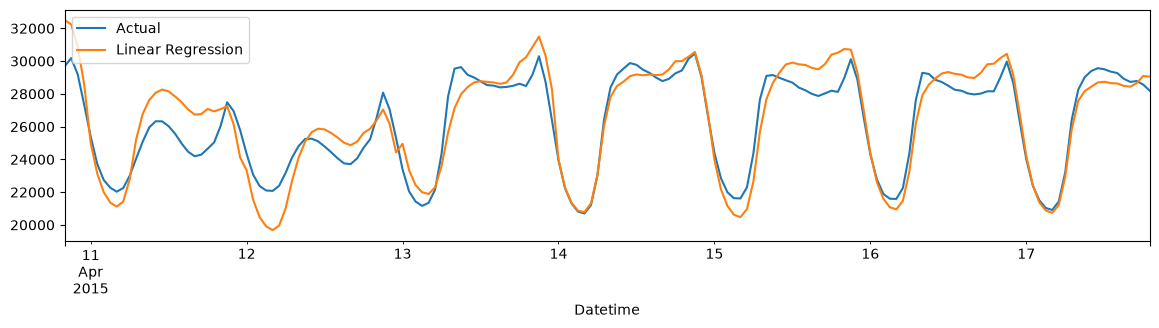

In [4]:
plt.figure(figsize=(14, 3))
y_test.iloc[:24 * 7].plot(label="Actual")
pd.Series(pred_lr, index=y_test.index).iloc[:24 * 7].plot(label="Linear Regression")
plt.legend(); plt.show()

### compute residual

In [5]:
residuals = y_test - pred_lr

print("Mean residual:", residuals.mean().round(1))
print("Std of residuals:", residuals.std().round(1))
print("Largest under-prediction:", residuals.max().round(0), "at", residuals.idxmax())
print("Largest over-prediction:", residuals.min().round(0), "at", residuals.idxmin())

Mean residual: 96.1
Std of residuals: 2238.3
Largest under-prediction: 10929.0 at 2018-07-16 15:00:00
Largest over-prediction: -10708.0 at 2017-05-20 16:00:00


### four residual plots

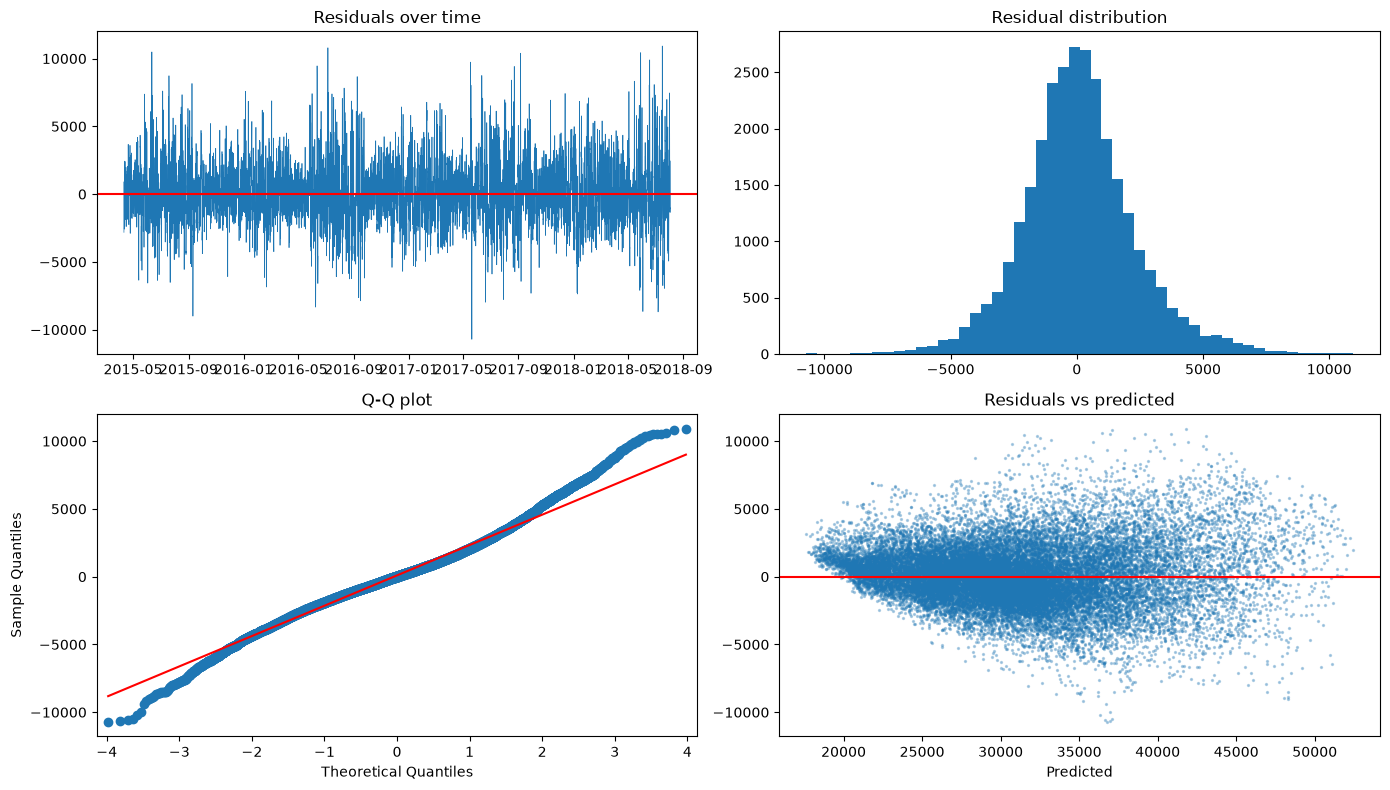

In [6]:
import statsmodels.api as sm

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

# Over time
ax[0, 0].plot(residuals.index, residuals, lw=0.5)
ax[0, 0].axhline(0, color="red")
ax[0, 0].set_title("Residuals over time")

# Distribution
ax[0, 1].hist(residuals, bins=50)
ax[0, 1].set_title("Residual distribution")

# Q-Q plot (normality)
sm.qqplot(residuals, line="s", ax=ax[1, 0])
ax[1, 0].set_title("Q-Q plot")

# Residuals vs predicted
ax[1, 1].scatter(pred_lr, residuals, s=2, alpha=0.3)
ax[1, 1].axhline(0, color="red")
ax[1, 1].set_title("Residuals vs predicted")
ax[1, 1].set_xlabel("Predicted")

plt.tight_layout()
plt.show()

### where is the error largest

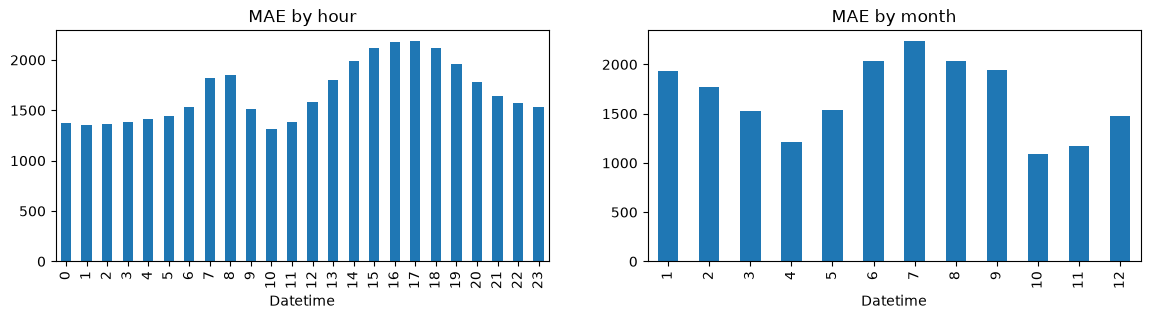

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3))
residuals.abs().groupby(residuals.index.hour).mean().plot(kind="bar", ax=ax[0], title="MAE by hour")
residuals.abs().groupby(residuals.index.month).mean().plot(kind="bar", ax=ax[1], title="MAE by month")
plt.show()